# Bootstrap das avaliações de usuários

Este notebook reamostra **conjuntos completos de avaliação**. A unidade estatística é a chave `(profile_id, resume_id, request_id, recommendation_engine)`; portanto, as 5 avaliações de um motor permanecem juntas durante cada reamostragem.

O intervalo de confiança é percentílico, com 95% de confiança (`2,5%` e `97,5%`). A comparação entre BM25 e Jaccard usa bootstrap pareado: em cada iteração, os mesmos conjuntos comuns são sorteados para os dois motores.

## Como funciona

O Bootstrap é um método de reamostragem que permite estimar a distribuição de uma estatística (como a média ou mediana) a partir de uma amostra de dados. No contexto das avaliações de usuários, o bootstrap é usado para gerar múltiplas amostras de avaliação, permitindo calcular intervalos de confiança para métricas de desempenho dos motores de recomendação.

## Exemplo com base no nosso contexto

Considerem que 50 usuários avaliaram recomendações de dois motores diferentes (BM25 e Jaccard). Cada usuário avaliou 5 recomendações de cada motor. No exemplo abaixo, considere que são apenas as avaliações de Jaccard:

| Usuário | Motor | Binary Relevance | Adherence Score | Clarity Score |
|---------|-------|------------|------------|------------|
| 1       | Jaccard  | [1,0,1,0,0] | [4, 5, 3, 4, 5] | [4, 5, 2, 1, 2] |
| 2       | Jaccard | [1,1,1,0,0] | [3, 4, 2, 3, 4] | [3, 1, 1, 3, 4] |
| 3       | Jaccard  | [1,0,1,1,0] | [5, 5, 4, 5, 5] | [5, 5, 4, 4, 4] |
| 4       | Jaccard | [1,0,1,0,1] | [4, 4, 3, 4, 4] | [4, 3, 3, 2, 5] |
....

A ideia do boot strap é gerar várias amostras de avaliação a partir dos dados originais, mantendo a estrutura das avaliações por usuário e motor. Em cada iteração do bootstrap, sorteamos aleatoriamente usuários com reposição, garantindo que cada conjunto de avaliações de um usuário permaneça junto.

Sendo assim, no exemplo anterior:
| Usuário | Motor | Binary Relevance | Adherence Score | Clarity Score |
|---------|-------|------------|------------|------------|
| **1**       | Jaccard  | [1,0,1,0,0] | [4, 5, 3, 4, 5] | [4, 5, 2, 1, 2] |
| **1**       | Jaccard  | [1,0,1,0,0] | [4, 5, 3, 4, 5] | [4, 5, 2, 1, 2] |
| 3       | Jaccard  | [1,0,1,1,0] | [5, 5, 4, 5, 5] | [5, 5, 4, 4, 4] |
| 4       | Jaccard | [1,0,1,0,1] | [4, 4, 3, 4, 4] | [4, 3, 3, 2, 5] |
....

Original: [U1, U2, U3, U4,....]

Reamostragem: [**U1**,**U1**,U3,U4,....] (com reposição, alguns usuários podem aparecer mais de uma vez, como **U1**)


**Importante:** Se estamos considerando um conjunto de 50 usuários, cada reamostragem também terá 50 usuários, mas alguns podem aparecer mais de uma vez e outros podem não aparecer.

## Base científica
A base do bootstrap parte da ideia que por mais que gerar apenas algumas amostras possa ser, de fato, aleatório, se geramos um número muito maior como 1000 ou 10.000, podemos ter uma boa aproximação da distribuição real da estatística que estamos interessados em estimar. Isso se aplica como a lei dos grandes números, que mostra que, em jogos de azar, se a probabilidade de vencer é de 48% e de perder é de 52%, se jogarmos 1000 ou 10.000 vezes, a proporção de vitórias tende a se aproximar de 48% e a proporção de derrotas tende a se aproximar de 52%.



In [25]:
%pip install numpy pandas pymongo matplotlib

Note: you may need to restart the kernel to use updated packages.


In [26]:
# Se necessário, execute uma vez no ambiente do notebook:
# %pip install pymongo pandas numpy matplotlib python-dotenv

# Bibliotecas usadas para configuração, manipulação tabular e acesso ao MongoDB.
import os
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

# As variáveis de conexão podem ser fornecidas pelo ambiente; os valores
# padrão permitem executar localmente quando o MongoDB está no host padrão.
MONGO_URI = os.environ.get('MONGO_URI', 'mongodb://localhost:27017')
MONGO_DATABASE = os.environ.get('MONGO_DATABASE', 'ors')
# Engines incluídos na análise e parâmetros comuns do bootstrap.
ENGINES = ('bm25', 'jaccard')
TOP_N_PER_ENGINE = 5
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
CI_LEVEL = 0.95

# None consulta todo o período. Quando preenchidos, os limites devem usar
# objetos datetime com timezone UTC; o limite final é exclusivo.
START_AT = datetime(2026, 9, 27, 0, 0, 0, tzinfo=timezone.utc)
END_AT = datetime(2026, 11, 1, 0, 0, 0, tzinfo=timezone.utc)


## 1. Leitura do MongoDB

Os documentos de `user_evaluations` são achatados apenas para validação e para os resumos dos três critérios. As métricas de ranking vêm de `recommendation_request_metrics`, pois são os valores locais já calculados para cada conjunto.

In [27]:
# KEY_COLUMNS identifica um conjunto de recomendações produzido por um motor.
KEY_COLUMNS = ['profile_id', 'resume_id', 'request_id', 'recommendation_engine']
# Estas métricas já calculadas no MongoDB serão usadas nas agregações posteriores.
# DCG e IDCG não são incluídas porque são componentes internos do NDCG.
METRIC_COLUMNS = ['precision_at_k', 'ap_at_k', 'reciprocal_rank_at_k', 'ndcg_at_k', 'ep_at_k']
# Campos mínimos necessários para validar cada item avaliado pelo usuário.
REQUIRED_ITEM_COLUMNS = ['opportunity_id', 'applied', 'adherence_score', 'clarity_score']

def build_query():
    """Monta a consulta dos documentos de avaliação dos engines escolhidos."""
    # O filtro temporal é aplicado ao momento de avaliação dos itens.
    query = {
        'recommendation_engine': {'$in': list(ENGINES)},
        'status': 'completed',
    }
    evaluated_at = {}
    if START_AT is not None:
        evaluated_at['$gte'] = START_AT
    if END_AT is not None:
        evaluated_at['$lt'] = END_AT
    if evaluated_at:
        query['items.evaluated_at'] = evaluated_at
    return query

# As duas coleções têm papéis diferentes: avaliações brutas e métricas locais.
client = MongoClient(MONGO_URI)
db = client[MONGO_DATABASE]
evaluations_collection = db['user_evaluations']
metrics_collection = db['recommendation_request_metrics']

# A projeção limita a leitura aos identificadores, itens e campos necessários.
# `_id` é omitido porque não participa da chave analítica.
evaluation_projection = {
    '_id': 0, **{column: 1 for column in KEY_COLUMNS},
    'requested_top_n': 1, 'items': 1,
}
evaluation_documents = list(evaluations_collection.find(build_query(), evaluation_projection))
# A quantidade retornada serve como verificação rápida da consulta.
len(evaluation_documents)


33

In [28]:
def flatten_evaluations(documents):
    """Converte documentos aninhados em uma linha por item avaliado."""
    rows = []
    for document in documents:
        # A normalização deixa o nome consistente nas mensagens de validação,
        # sem alterar o valor original mantido na chave do documento.
        engine = str(document.get('recommendation_engine', '')).lower()
        items = document.get('items') or []
        # Valida a estrutura antes de acessar os campos dos itens.
        missing = [column for column in REQUIRED_ITEM_COLUMNS
                  if any(column not in item for item in items)]
        if missing:
            raise ValueError(f'Campos ausentes em {document}: {missing}')
        if len(items) != TOP_N_PER_ENGINE:
            raise ValueError(
                f'O conjunto {document.get("request_id")} / {engine} tem '
                f'{len(items)} itens; esperado: {TOP_N_PER_ENGINE}.'
            )
        # Os identificadores do documento são repetidos em cada item para
        # permitir agrupamento posterior por conjunto e engine.
        base = {column: document.get(column) for column in KEY_COLUMNS}
        for rank, item in enumerate(items, start=1):
            rows.append({
                **base, 'rank': rank,
                'opportunity_id': item['opportunity_id'],
                'applied': int(bool(item['applied'])),
                'adherence_score': int(item['adherence_score']),
                'clarity_score': int(item['clarity_score']),
                'evaluated_at': item.get('evaluated_at'),
            })
    # O DataFrame ainda está no nível dos itens; depois ele será agrupado
    # para validar que cada conjunto possui exatamente TOP_N_PER_ENGINE itens.
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError('Nenhuma avaliação encontrada para os engines configurados.')
    # Estas validações impedem que valores inválidos contaminem as métricas.
    if not frame['applied'].isin([0, 1]).all():
        raise ValueError('applied deve ser booleano ou 0/1.')
    if not frame['adherence_score'].between(1, 5).all() or not frame['clarity_score'].between(1, 5).all():
        raise ValueError('adherence_score e clarity_score devem estar entre 1 e 5.')
    return frame

# A tabela resultante será usada para validar a unidade de reamostragem.
evaluations = flatten_evaluations(evaluation_documents)
evaluations.groupby('recommendation_engine').size().rename('number_of_items')
display(evaluations.head())


,profile_id,resume_id,request_id,recommendation_engine,rank,opportunity_id,applied,adherence_score,clarity_score,evaluated_at
0,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,1,bbe46f3e-0eb7-4cbf-9932-ee2511a07e91,0,3,3,2026-09-28 20:19:20.798
1,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,2,5527015a-7861-4d48-9098-5b681ff2b443,0,3,3,2026-09-28 20:19:25.293
2,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,3,c7152838-bf68-4d3c-ab79-8c0ab46845ef,0,3,3,2026-09-28 20:19:29.353
3,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,4,ecb7d0c0-e9eb-4dbb-8536-f8d6b0975568,0,3,3,2026-09-28 20:19:33.124
4,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,5,59639a56-0e3c-4f56-a4be-79b4ae5c08d7,0,3,3,2026-09-28 20:19:36.095


In [29]:
# As métricas locais são lidas pela mesma chave do conjunto de avaliação.
# Isso permite combinar o resultado calculado pelo sistema com a validação
# das avaliações recebidas dos usuários.
metrics_projection = {
    '_id': 0, **{column: 1 for column in KEY_COLUMNS},
    'metrics': 1,
}
metrics_documents = list(metrics_collection.find(
    {'recommendation_engine': {'$in': list(ENGINES)}},
    metrics_projection,
))

def flatten_local_metrics(documents):
    """Achata o campo aninhado `metrics` em colunas tabulares."""
    rows = []
    for document in documents:
        # Mantém a mesma chave usada em `evaluations` para a junção 1:1.
        row = {column: document.get(column) for column in KEY_COLUMNS}
        row.update({metric: (document.get('metrics') or {}).get(metric)
                    for metric in METRIC_COLUMNS})
        rows.append(row)
    return pd.DataFrame(rows)

local_metrics = flatten_local_metrics(metrics_documents)
if local_metrics.empty:
    raise ValueError('Nenhuma métrica local encontrada.')

# Cada conjunto precisa conter exatamente TOP_N_PER_ENGINE itens avaliados.
set_counts = evaluations.groupby(KEY_COLUMNS).size()
invalid_counts = set_counts[set_counts != TOP_N_PER_ENGINE]
if not invalid_counts.empty:
    raise ValueError(f'Conjuntos sem exatamente {TOP_N_PER_ENGINE} avaliações:\n{invalid_counts}')

# A métrica local deve ser única por conjunto; em caso de duplicidade,
# conserva-se o último registro recebido.
local_metrics = local_metrics.drop_duplicates(KEY_COLUMNS, keep='last')
# A junção interna remove conjuntos sem avaliação correspondente ou sem
# métricas locais, garantindo que `data` seja analisável nas seções seguintes.
data = local_metrics.merge(
    evaluations.groupby(KEY_COLUMNS, as_index=False).size().drop(columns='size'),
    on=KEY_COLUMNS, how='inner', validate='one_to_one',
)
data[KEY_COLUMNS + METRIC_COLUMNS]


,profile_id,resume_id,request_id,recommendation_engine,precision_at_k,ap_at_k,reciprocal_rank_at_k,ndcg_at_k,ep_at_k
0,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,jaccard,0.2,1.000000,1.000000,1.000000,0.0
1,c614e846-d105-4113-88c0-b946dc978216,fba09d53-96bc-4853-86f4-4124eac720e0,9ba917e3-fa71-4c18-86cb-204854fde9dc,bm25,0.0,0.000000,0.000000,1.000000,0.0
2,73cf2bcb-1629-4444-8a6b-e536299149b8,b12d88af-8ac2-4993-8694-1a089141db62,e9cbc743-52f1-4dc1-81b5-0dfb14c5be12,jaccard,0.0,0.000000,0.000000,0.861010,0.4
3,73cf2bcb-1629-4444-8a6b-e536299149b8,b12d88af-8ac2-4993-8694-1a089141db62,e9cbc743-52f1-4dc1-81b5-0dfb14c5be12,bm25,0.0,0.000000,0.000000,0.928799,0.8
4,c46407be-22a9-4e5e-928e-7adcc2757bde,14dbfb98-babd-4689-8276-3b12c2836ea4,11d47cd6-5001-4691-8e53-3ea562d86402,jaccard,0.2,0.200000,0.200000,0.872549,1.0
5,c46407be-22a9-4e5e-928e-7adcc2757bde,14dbfb98-babd-4689-8276-3b12c2836ea4,11d47cd6-5001-4691-8e53-3ea562d86402,bm25,0.2,0.250000,0.250000,0.810696,0.6
6,ee9267cb-07f7-4128-a39d-ffe2f7b9f4ca,693c5a04-42fd-47e6-a902-c74450170bcd,4b282f25-afa9-4fcf-8aad-6e63bb8b66bd,jaccard,0.6,0.533333,0.500000,0.826463,0.8
7,ee9267cb-07f7-4128-a39d-ffe2f7b9f4ca,693c5a04-42fd-47e6-a902-c74450170bcd,4b282f25-afa9-4fcf-8aad-6e63bb8b66bd,bm25,0.4,0.583333,0.500000,0.860995,0.8
8,8ed87521-8901-4a70-9aa9-ad7d8d866f74,77ca5f65-79aa-47ec-852d-04b094a10d3b,6f35f8a8-1c56-4692-b634-fccbdb82a344,jaccard,0.2,0.500000,0.500000,0.853918,0.4
9,8ed87521-8901-4a70-9aa9-ad7d8d866f74,77ca5f65-79aa-47ec-852d-04b094a10d3b,6f35f8a8-1c56-4692-b634-fccbdb82a344,bm25,0.0,0.000000,0.000000,0.769899,0.0


## 2. Efetuando o Bootstrap

Cada linha de `data` representa os resultados das métricas locais associadas as avaliações de um usuário de um top-N para um motor. Assim, `rng.integers` sorteia índices de conjuntos, ou seja, sorteia pelo usuário e um motor, e não índices das 5 avaliações internas.

Correspondência com o ADR: `MAP = mean(ap_at_k)`, `Hit Ratio = mean(reciprocal_rank_at_k > 0)`, `MRR = mean(reciprocal_rank_at_k)`, `NDCG = mean(ndcg_at_k)` e `EP@K = mean(ep_at_k)`. O `Hit Ratio` é uma derivação operacional, porque ele não aparece explicitamente no documento de métricas locais.

In [30]:
def global_metrics(sample):
    """Agrega as métricas de um motor em uma única amostra bootstrap."""
    # Cada linha de `sample` representa um conjunto completo de avaliação.
    # Portanto, a agregação é feita entre conjuntos, e não entre itens individuais.
    rr = sample['reciprocal_rank_at_k'].to_numpy(dtype=float)
    return {
        # MAP é a média do Average Precision de cada conjunto.
        'map': sample['ap_at_k'].mean(),
        # Hit Ratio é a proporção de conjuntos em que pelo menos um item relevante foi retornado.
        'hit_ratio': np.mean(rr > 0),
        # Neste nível de agregação, MRR é a média do Reciprocal Rank.
        'mrr': rr.mean(),
        'ndcg_at_k': sample['ndcg_at_k'].mean(),
        'ep_at_k': sample['ep_at_k'].mean(),
    }

def bootstrap_engine(engine_data, n_bootstrap=N_BOOTSTRAP, seed=RANDOM_SEED):
    """Gera a distribuição bootstrap das métricas de um motor."""
    if engine_data.empty:
        raise ValueError('Engine sem dados.')
    # O índice representa conjuntos de avaliação; reset_index evita carregar
    # os identificadores originais para dentro da reamostragem posicional.
    values = engine_data.reset_index(drop=True)
    rng = np.random.default_rng(seed)
    # Cada linha de `indices` é uma nova amostra com reposição e mantém
    # o mesmo tamanho da amostra observada.
    indices = rng.integers(0, len(values), size=(n_bootstrap, len(values)))
    result = {name: np.empty(n_bootstrap) for name in global_metrics(values)}
    for iteration, sample_indices in enumerate(indices):
        # O mesmo sorteio de conjuntos é usado para todas as métricas
        # daquela iteração, preservando a dependência entre elas.
        metrics = global_metrics(values.iloc[sample_indices])
        for name, value in metrics.items():
            result[name][iteration] = value
    return pd.DataFrame(result)

def confidence_interval(samples, level=CI_LEVEL):
    """Calcula a estimativa média e o intervalo percentílico."""
    alpha = 1 - level
    return pd.Series({
        'estimate': np.mean(samples),
        'ci_low': np.quantile(samples, alpha / 2),
        'ci_high': np.quantile(samples, 1 - alpha / 2),
    })

print("###JACCARD###")
display(global_metrics(data[data['recommendation_engine'] == "jaccard"].reset_index(drop=True)))
print("###BM25###")
display(global_metrics(data[data['recommendation_engine'] == "bm25"].reset_index(drop=True)))


# Uma distribuição independente é gerada para cada motor.
bootstrap_distributions = {
    engine: bootstrap_engine(data[data['recommendation_engine'] == engine])
    for engine in ENGINES
}

# Resume cada distribuição bootstrap em média, limite inferior e superior.
confidence_tables = []
for engine, distribution in bootstrap_distributions.items():
    table = distribution.apply(confidence_interval).T
    table.insert(0, 'recommendation_engine', engine)
    table.insert(1, 'n_sets', len(data[data['recommendation_engine'] == engine]))
    confidence_tables.append(table.reset_index(names='metric'))

confidence_results = pd.concat(confidence_tables, ignore_index=True)
confidence_results

###JACCARD###


{'map': np.float64(0.46592592592592585),
 'hit_ratio': np.float64(0.7333333333333333),
 'mrr': np.float64(0.45777777777777773),
 'ndcg_at_k': np.float64(0.892020866999065),
 'ep_at_k': np.float64(0.4266666666666668)}

###BM25###


{'map': np.float64(0.3675),
 'hit_ratio': np.float64(0.6),
 'mrr': np.float64(0.38),
 'ndcg_at_k': np.float64(0.895679203776727),
 'ep_at_k': np.float64(0.46666666666666673)}

,metric,recommendation_engine,n_sets,estimate,ci_low,ci_high
0,map,bm25,15,0.367701,0.188056,0.558340
1,hit_ratio,bm25,15,0.600187,0.333333,0.866667
2,mrr,bm25,15,0.379978,0.180000,0.596667
3,ndcg_at_k,bm25,15,0.895648,0.856831,0.932339
4,ep_at_k,bm25,15,0.467313,0.293333,0.640000
5,map,jaccard,15,0.465374,0.277037,0.655556
6,hit_ratio,jaccard,15,0.732420,0.466667,0.933333
7,mrr,jaccard,15,0.457182,0.268889,0.646667
8,ndcg_at_k,jaccard,15,0.892189,0.847921,0.934919
9,ep_at_k,jaccard,15,0.427352,0.293333,0.573333


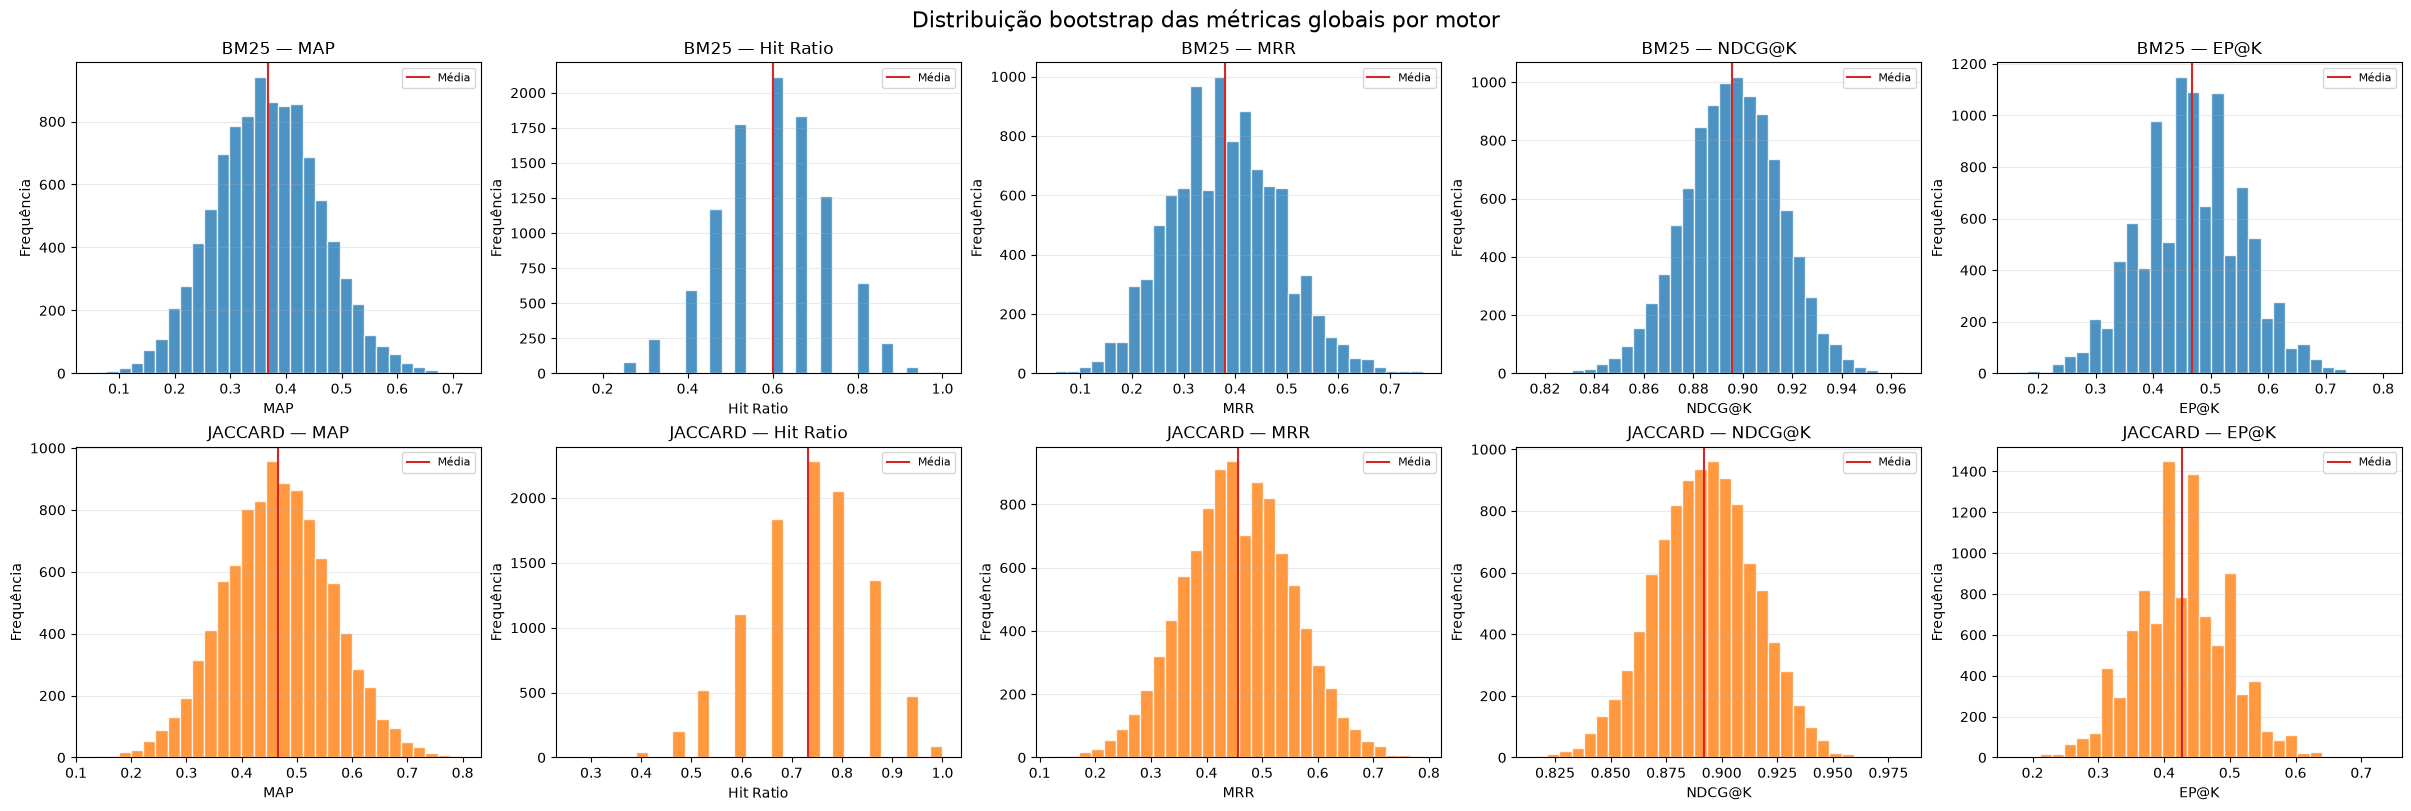

In [31]:
# Cada DataFrame contém uma linha por iteração do bootstrap de um motor.
# Os histogramas mostram como cada métrica varia entre as 10.000 iterações.
# Distribuições das métricas globais por motor (10 histogramas)
metric_labels = {
    'map': 'MAP',
    'hit_ratio': 'Hit Ratio',
    'mrr': 'MRR',
    'ndcg_at_k': 'NDCG@K',
    'ep_at_k': 'EP@K',
}

fig, axes = plt.subplots(2, 5, figsize=(24, 8), constrained_layout=True)
# Cada linha da grade corresponde a um motor; cada coluna corresponde a uma métrica.
for row, engine in zip(axes, ENGINES):
    distribution = bootstrap_distributions[engine]
    for ax, (metric, label) in zip(row, metric_labels.items()):
        ax.hist(distribution[metric], bins=30, alpha=0.8,
                color={'bm25': '#1f77b4', 'jaccard': '#ff7f0e'}[engine],
                edgecolor='white')
        # A linha vermelha marca a média da distribuição bootstrap.
        ax.axvline(distribution[metric].mean(), color='#d62728',
                   linestyle='-', linewidth=1.5, label='Média')
        ax.set_title(f'{engine.upper()} — {label}')
        ax.set_xlabel(label)
        ax.set_ylabel('Frequência')
        ax.grid(axis='y', alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle('Distribuição bootstrap das métricas globais por motor', fontsize=16)
plt.show()
plt.close(fig)

## 3. Testes de Significância

Se fizemos, em paralelo, o bootstrap para BM25 e Jaccard, podemos comparar os resultados de cada métrica. A ideia é verificar se a diferença entre as métricas dos dois motores é estatisticamente significativa.

Considerando $J$ como quem agrega as métricas globais para um dado conjunto de avaliações de $N$ usuários para Jaccard, enquanto $B$ segue a mesma regra para BM25, podemos calcular a diferença entre as métricas de interesse para cada reamostragem. Por exemplo, se estamos interessados na métrica `MAP`, podemos calcular:
$$
\Delta MAP = MAP(J) - MAP(B)
$$

| Iteração | MAP(J) | MAP(B) | ΔMAP |
|-----------|--------|--------|------ |
| 1         | 0.45   | 0.40   | 0.05 |
| 2         | 0.50   | 0.42   | 0.08 |
....

In [32]:
# Comparação pareada: BM25 - Jaccard

# A comparação pareada exige que os dois motores usem a mesma codificação.
data = data.copy()
data['recommendation_engine'] = (
    data['recommendation_engine'].astype(str).str.strip().str.lower()
)
REQUEST_KEY_COLUMNS = KEY_COLUMNS[:-1]
# Identifica as chaves de avaliação presentes simultaneamente nos dois motores.
# A unidade pareada é a trinca profile_id + resume_id + request_id.
common_keys = (
    set(data.loc[data['recommendation_engine'] == 'bm25', REQUEST_KEY_COLUMNS]
        .itertuples(index=False, name=None))
    & set(data.loc[data['recommendation_engine'] == 'jaccard', REQUEST_KEY_COLUMNS]
        .itertuples(index=False, name=None))
)
if not common_keys:
    raise ValueError('Não há conjuntos comuns para comparação pareada.')

# Mantém apenas os conjuntos comuns; assim, cada linha terá observações dos
# dois motores quando os dados forem reorganizados para o formato largo.
common = data[data[REQUEST_KEY_COLUMNS].apply(tuple, axis=1).isin(common_keys)].copy()
# O pivot coloca BM25 e Jaccard lado a lado para cada conjunto pareado.
wide = common.pivot(
    index=REQUEST_KEY_COLUMNS,
    columns='recommendation_engine',
    values=METRIC_COLUMNS,
)

# O pandas pode produzir o MultiIndex como (engine, métrica) ou (métrica, engine).
# Padronizamos para que o bootstrap use sempre (métrica, engine).
expected_column = (METRIC_COLUMNS[0], 'bm25')
alternative_column = ('bm25', METRIC_COLUMNS[0])
if expected_column not in wide.columns and alternative_column in wide.columns:
    wide = wide.swaplevel(0, 1, axis=1)

# Falhar cedo aqui evita produzir diferenças silenciosamente com uma métrica
# ou um motor ausente.
required_columns = pd.MultiIndex.from_product(
    [METRIC_COLUMNS, ['bm25', 'jaccard']]
)
missing_columns = required_columns.difference(wide.columns)
if not missing_columns.empty:
    raise ValueError(
        f'Colunas necessárias ausentes após o pivot: {list(missing_columns)}. '
        f'Colunas encontradas: {list(wide.columns)}'
    )
wide = wide.sort_index(axis=1).dropna()

def paired_bootstrap(wide_data, n_bootstrap=N_BOOTSTRAP, seed=RANDOM_SEED):
    """Gera diferenças bootstrap usando os mesmos índices nos dois motores."""
    rng = np.random.default_rng(seed)
    n = len(wide_data)
    # O sorteio é feito sobre conjuntos comuns, não separadamente por motor.
    # Isso preserva o pareamento durante todas as iterações.
    indices = rng.integers(0, n, size=(n_bootstrap, n))
    result = {}
    # Para estas métricas, a diferença é calculada conjunto a conjunto e
    # depois agregada pela média em cada reamostragem.
    for metric in ['ap_at_k', 'ndcg_at_k', 'ep_at_k']:
        bm25 = wide_data[(metric, 'bm25')].to_numpy()[indices]
        jaccard = wide_data[(metric, 'jaccard')].to_numpy()[indices]
        result[metric] = (bm25 - jaccard).mean(axis=1)
    # MRR usa diretamente o Reciprocal Rank; o Hit Ratio transforma esse
    # valor em uma indicação binária de acerto antes de calcular a média.
    bm25_rr = wide_data[('reciprocal_rank_at_k', 'bm25')].to_numpy()[indices]
    jaccard_rr = wide_data[('reciprocal_rank_at_k', 'jaccard')].to_numpy()[indices]
    result['mrr'] = (bm25_rr - jaccard_rr).mean(axis=1)
    result['hit_ratio'] = ((bm25_rr > 0).mean(axis=1) - (jaccard_rr > 0).mean(axis=1))
    return pd.DataFrame(result)

# Cada coluna contém 10.000 diferenças, uma por iteração do bootstrap pareado.
paired_distribution = paired_bootstrap(wide)
paired_results = paired_distribution.apply(confidence_interval).T.reset_index(names='metric')
paired_results.insert(1, 'comparison', 'bm25 - jaccard')
paired_results.insert(2, 'n_common_sets', len(wide))
paired_results

,metric,comparison,n_common_sets,estimate,ci_low,ci_high
0,ap_at_k,bm25 - jaccard,15,-0.098802,-0.330558,0.119264
1,ndcg_at_k,bm25 - jaccard,15,0.003386,-0.053958,0.060666
2,ep_at_k,bm25 - jaccard,15,0.040025,-0.106667,0.186667
3,mrr,bm25 - jaccard,15,-0.078423,-0.336667,0.177778
4,hit_ratio,bm25 - jaccard,15,-0.132620,-0.333333,0.000000


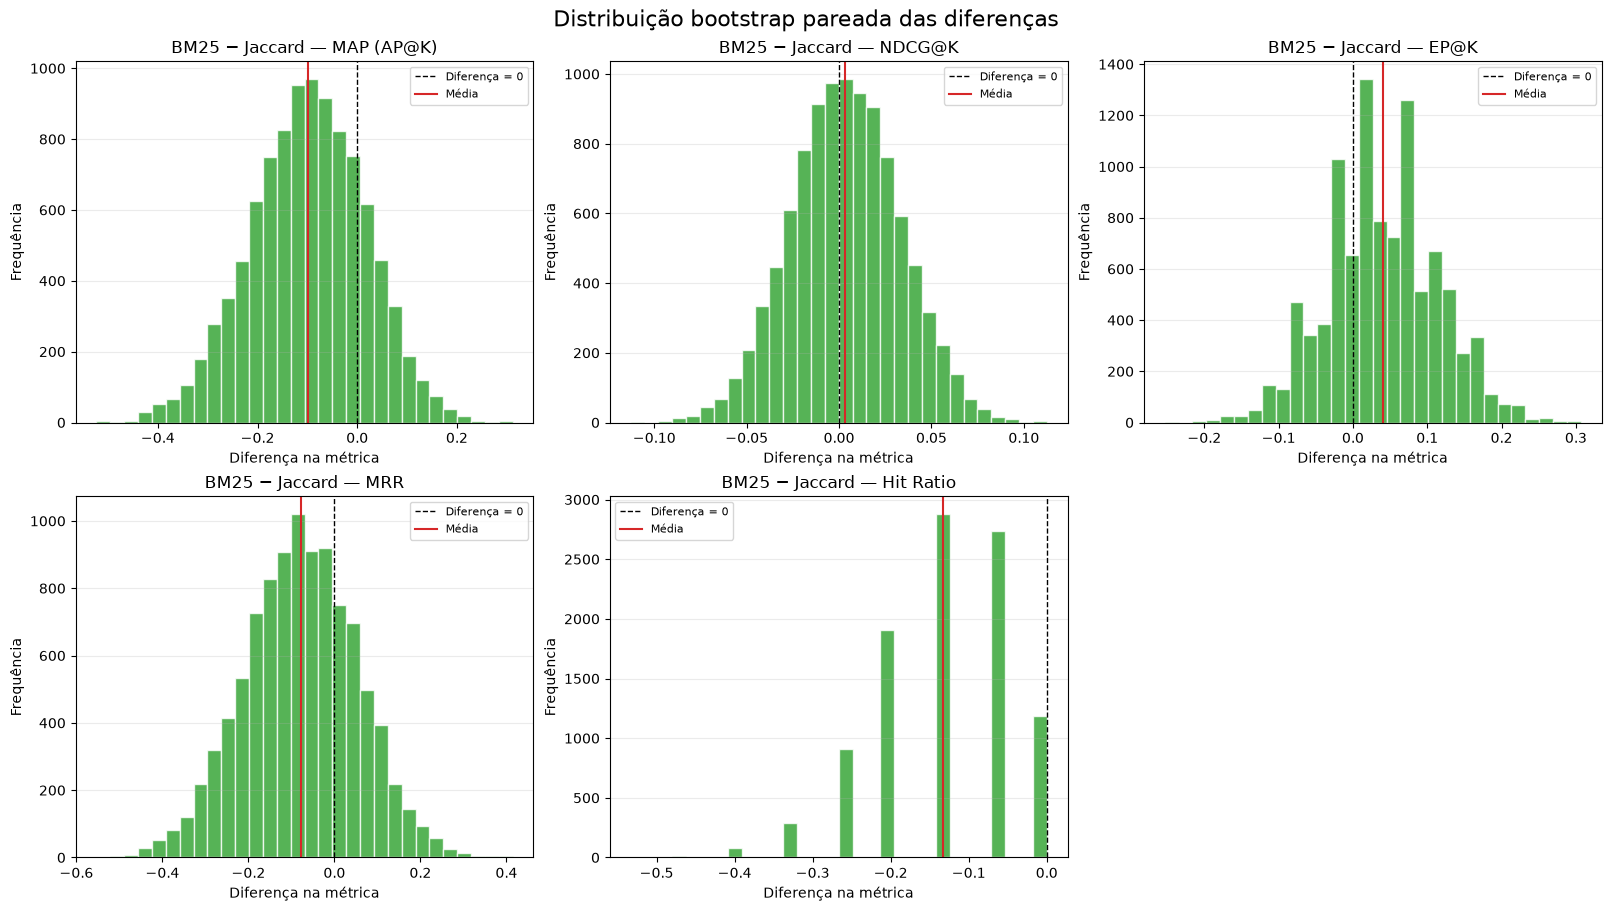

In [33]:
# Cada coluna de `paired_distribution` contém a diferença BM25 - Jaccard
# observada em uma iteração do bootstrap pareado.
# Distribuições das diferenças pareadas por iteração (5 histogramas)
paired_metric_labels = {
    'ap_at_k': 'MAP (AP@K)',
    'ndcg_at_k': 'NDCG@K',
    'ep_at_k': 'EP@K',
    'mrr': 'MRR',
    'hit_ratio': 'Hit Ratio',
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, (metric, label) in zip(axes.flat, paired_metric_labels.items()):
    ax.hist(paired_distribution[metric], bins=30, color='#2ca02c',
            alpha=0.8, edgecolor='white')
    # Zero representa ausência de diferença entre os motores.
    ax.axvline(0, color='black', linestyle='--', linewidth=1,
               label='Diferença = 0')
    # A linha vermelha mostra a diferença média estimada.
    ax.axvline(paired_distribution[metric].mean(), color='#d62728',
               linestyle='-', linewidth=1.5, label='Média')
    ax.set_title(f'BM25 − Jaccard — {label}')
    ax.set_xlabel('Diferença na métrica')
    ax.set_ylabel('Frequência')
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8)

# O sexto espaço da grade 2x3 fica vazio porque há cinco métricas.
axes.flat[-1].axis('off')
fig.suptitle('Distribuição bootstrap pareada das diferenças', fontsize=16)
plt.show()
plt.close(fig)

## 3. Interpretação e exportação

`estimate` é a média da distribuição bootstrap; `ci_low` e `ci_high` são os percentis 2,5% e 97,5%. Na comparação pareada, um intervalo que não contenha zero indica evidência de diferença entre os motores neste procedimento, mas não substitui um teste estatístico ou uma análise de poder.

A amostragem é feita pela trinca mais o motor. Se a unidade experimental desejada for o usuário independentemente de múltiplas requests, agregue primeiro por `profile_id` e então reamostre essa unidade; isso é uma decisão estatística diferente.

In [34]:
confidence_results.to_csv('bootstrap_confidence_intervals_by_engine.csv', index=False)
paired_results.to_csv('bootstrap_confidence_intervals_bm25_vs_jaccard.csv', index=False)

print('Resultados exportados:')
print('- bootstrap_confidence_intervals_by_engine.csv')
print('- bootstrap_confidence_intervals_bm25_vs_jaccard.csv')

Resultados exportados:
- bootstrap_confidence_intervals_by_engine.csv
- bootstrap_confidence_intervals_bm25_vs_jaccard.csv


### Referências
- [An Intelligent Job Matching Platform Using Knowledge Graphs, Semantic Search and
Explainable AI](https://arxiv.org/abs/2603.14558)
- [Bootstrapping main ideas](https://youtu.be/Xz0x-8-cgaQ?si=_3uaSHJE21KILkne)
- [Bootstrap Resampling - Explained](https://youtu.be/41ST4JdMrpA?si=gdKG08lefYHa9SKs)